# Projeto de Modelagem Estatística — Preço de imóveis em Ames (Iowa, EUA)

## 1. Dataset e objetivo

**Dataset:** *Ames Housing*, com 2.930 vendas de casas na cidade de Ames (EUA) entre 2006 e 2010. É um dataset público, criado pelo professor Dean De Cock para o ensino de regressão.

**Por que escolhemos:**
- tem uma variável numérica de interesse prático, o **preço de venda**, que podemos explicar com regressão linear;
- tem variáveis numéricas e categóricas, o que permite usar testes de hipóteses diferentes;
- tem **valores ausentes**, que precisam ser tratados;
- tem a **data da venda**, o que permite treinar o modelo com os anos anteriores e prever o ano seguinte.

**Pergunta do projeto:** quais características mais influenciam o preço de uma casa, e como isso ajuda quem quer vender, comprar ou reformar?

O dataset original tem 82 colunas. Para manter a análise objetiva, usamos **20 colunas** ligadas às características que um comprador normalmente avalia: tamanho, qualidade, idade, garagem, lareira, ar-condicionado e localização.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

## 2. Leitura dos dados e renomeação das colunas

As colunas originais estão em inglês e com nomes abreviados. Selecionamos as 20 que vamos usar e demos nomes em português.

In [2]:
dados_brutos = pd.read_csv('AmesHousing.csv')
print(dados_brutos.shape)

nomes = {
    'SalePrice': 'preco',
    'Gr Liv Area': 'area_util',
    'Total Bsmt SF': 'area_porao',
    'Lot Area': 'area_lote',
    'Lot Frontage': 'frente_lote',
    'Overall Qual': 'qualidade',
    'Overall Cond': 'conservacao',
    'Year Built': 'ano_construcao',
    'Year Remod/Add': 'ano_reforma',
    'Yr Sold': 'ano_venda',
    'Mo Sold': 'mes_venda',
    'Full Bath': 'banheiros_completos',
    'Half Bath': 'lavabos',
    'Bedroom AbvGr': 'quartos',
    'Garage Cars': 'vagas_garagem',
    'Garage Type': 'tipo_garagem',
    'Fireplaces': 'lareiras',
    'Central Air': 'ar_central',
    'Neighborhood': 'bairro',
    'Bldg Type': 'tipo_imovel',
}
df = dados_brutos[list(nomes)].rename(columns=nomes)
df.head()

(2930, 82)


,preco,area_util,area_porao,area_lote,frente_lote,qualidade,conservacao,ano_construcao,ano_reforma,ano_venda,mes_venda,banheiros_completos,lavabos,quartos,vagas_garagem,tipo_garagem,lareiras,ar_central,bairro,tipo_imovel
0,215000,1656,"1,080.00",31770,141.00,6,5,1960,1960,2010,5,1,0,3,2.00,Attchd,2,Y,NAmes,1Fam
1,105000,896,882.00,11622,80.00,5,6,1961,1961,2010,6,1,0,2,1.00,Attchd,0,Y,NAmes,1Fam
2,172000,1329,"1,329.00",14267,81.00,6,6,1958,1958,2010,6,1,1,3,1.00,Attchd,0,Y,NAmes,1Fam
3,244000,2110,"2,110.00",11160,93.00,7,5,1968,1968,2010,4,2,1,3,2.00,Attchd,2,Y,NAmes,1Fam
4,189900,1629,928.00,13830,74.00,5,5,1997,1998,2010,3,2,1,3,2.00,Attchd,1,Y,Gilbert,1Fam


| Coluna | Significado |
|---|---|
| `preco` | preço de venda (US$) |
| `area_util`, `area_porao`, `area_lote` | áreas da casa (sem o porão), do porão e do terreno |
| `frente_lote` | largura da frente do terreno |
| `qualidade` | nota de 1 a 10 para material e acabamento |
| `conservacao` | nota de 1 a 10 para o estado de conservação |
| `ano_construcao`, `ano_reforma`, `ano_venda`, `mes_venda` | datas |
| `banheiros_completos`, `lavabos`, `quartos`, `vagas_garagem`, `lareiras` | contagens |
| `tipo_garagem`, `ar_central`, `bairro`, `tipo_imovel` | categorias |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   preco                2930 non-null   int64  
 1   area_util            2930 non-null   int64  
 2   area_porao           2929 non-null   float64
 3   area_lote            2930 non-null   int64  
 4   frente_lote          2440 non-null   float64
 5   qualidade            2930 non-null   int64  
 6   conservacao          2930 non-null   int64  
 7   ano_construcao       2930 non-null   int64  
 8   ano_reforma          2930 non-null   int64  
 9   ano_venda            2930 non-null   int64  
 10  mes_venda            2930 non-null   int64  
 11  banheiros_completos  2930 non-null   int64  
 12  lavabos              2930 non-null   int64  
 13  quartos              2930 non-null   int64  
 14  vagas_garagem        2929 non-null   float64
 15  tipo_garagem         2773 non-null   o

## 3. Limpeza e tratamento dos dados

### 3.1 Valores ausentes

In [4]:
ausentes = df.isna().sum()
ausentes = ausentes[ausentes > 0].to_frame('quantidade')
ausentes['percentual'] = ausentes['quantidade'] / len(df) * 100
ausentes

,quantidade,percentual
area_porao,1,0.03
frente_lote,490,16.72
vagas_garagem,1,0.03
tipo_garagem,157,5.36


Cada coluna foi tratada de acordo com o **motivo** da ausência:

| Coluna | Tratamento | Justificativa |
|---|---|---|
| `tipo_garagem` (157) | categoria **"Sem garagem"** | No dicionário do dataset, o valor vazio significa que a casa **não tem garagem**. Não é um dado perdido, é uma informação. |
| `frente_lote` (490) | **mediana do bairro** | É um dado realmente faltante (17%). Lotes do mesmo bairro têm tamanhos parecidos, e a mediana não é afetada por lotes muito grandes. Excluir as linhas jogaria fora 17% dos dados. |
| `vagas_garagem` (1) e `area_porao` (1) | **mediana da coluna** | É apenas um caso em cada coluna, então o impacto é desprezível. |

In [5]:
df['tipo_garagem'] = df['tipo_garagem'].fillna('Sem garagem')
df['frente_lote'] = df['frente_lote'].fillna(df.groupby('bairro')['frente_lote'].transform('median'))
df['frente_lote'] = df['frente_lote'].fillna(df['frente_lote'].median())
df['vagas_garagem'] = df['vagas_garagem'].fillna(df['vagas_garagem'].median())
df['area_porao'] = df['area_porao'].fillna(df['area_porao'].median())
print('Valores ausentes restantes:', df.isna().sum().sum())

Valores ausentes restantes: 0


### 3.2 Inconsistências e valores extremos

- **Datas impossíveis:** verificamos se há casa reformada antes de ser construída ou vendida antes de ser construída. O ano de reforma errado foi igualado ao de construção; a casa vendida antes de ficar pronta (venda na planta) fica com idade zero na seção 4.
- **Casas com mais de 4.000 pés² de área útil:** o autor do dataset recomenda removê-las. São 5 casos, e alguns foram vendidos por preços muito baixos para o tamanho (vendas atípicas), o que distorce a reta de regressão.

Reforma antes da construção: 1
Venda antes da construção: 1
Área útil acima de 4000 pés²: 5


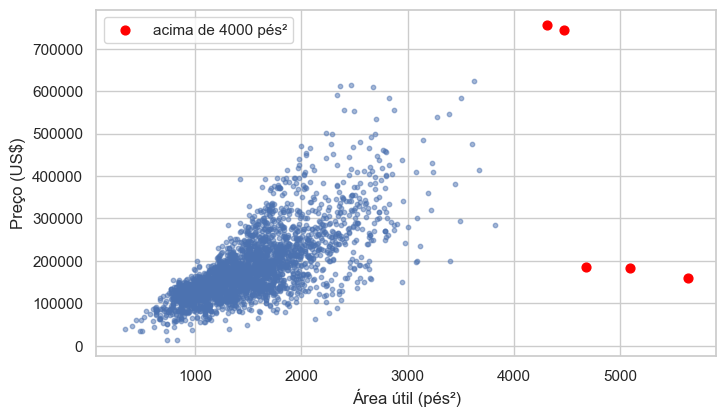

In [6]:
print('Reforma antes da construção:', (df['ano_reforma'] < df['ano_construcao']).sum())
print('Venda antes da construção:', (df['ano_venda'] < df['ano_construcao']).sum())
print('Área útil acima de 4000 pés²:', (df['area_util'] > 4000).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
extremos = df['area_util'] > 4000
ax.scatter(df.loc[~extremos, 'area_util'], df.loc[~extremos, 'preco'], s=10, alpha=0.5)
ax.scatter(df.loc[extremos, 'area_util'], df.loc[extremos, 'preco'], s=40, color='red', label='acima de 4000 pés²')
ax.set_xlabel('Área útil (pés²)')
ax.set_ylabel('Preço (US$)')
ax.legend()
plt.show()

In [7]:
df.loc[df['ano_reforma'] < df['ano_construcao'], 'ano_reforma'] = df['ano_construcao']
df = df[df['area_util'] <= 4000].copy()
print('Tamanho final da base:', len(df))

Tamanho final da base: 2925


### 3.3 Padronização de unidades e categorias

- Áreas convertidas de **pés² para m²** (1 pé² = 0,0929 m²) e a frente do lote de pés para metros (1 pé = 0,3048 m).
- Categorias traduzidas para português.

In [8]:
for coluna in ['area_util', 'area_porao', 'area_lote']:
    df[coluna] = df[coluna] * 0.092903
df['frente_lote'] = df['frente_lote'] * 0.3048

df['ar_central'] = df['ar_central'].map({'Y': 'Sim', 'N': 'Não'})
df['tipo_imovel'] = df['tipo_imovel'].map({'1Fam': 'Casa unifamiliar', '2fmCon': 'Casa convertida em duas',
                                           'Duplex': 'Duplex', 'TwnhsE': 'Geminada de ponta', 'Twnhs': 'Geminada de meio'})
df['tipo_garagem'] = df['tipo_garagem'].replace({'Attchd': 'Anexa', 'Detchd': 'Separada', 'BuiltIn': 'Embutida',
                                                 'Basment': 'No porão', 'CarPort': 'Cobertura aberta', '2Types': 'Dois tipos'})
df[['tipo_imovel', 'tipo_garagem', 'ar_central']].describe()

,tipo_imovel,tipo_garagem,ar_central
count,2925,2925,2925
unique,5,7,2
top,Casa unifamiliar,Anexa,Sim
freq,2420,1727,2729


## 4. Engenharia de variáveis

| Nova variável | Como foi criada | Para que serve |
|---|---|---|
| `area_total` | área útil + área do porão | representa o tamanho total construído |
| `idade` | ano da venda − ano de construção | o que importa para o comprador é a idade da casa **no momento da venda** |
| `reformada` | "Sim" se o ano de reforma é maior que o de construção | comparar casas reformadas e não reformadas |
| `banheiros` | banheiros completos + 0,5 × lavabos | junta duas colunas em uma só |
| `tem_lareira` | "Sim" se tem pelo menos uma lareira | usada no teste qui-quadrado |
| `preco_m2` | preço ÷ área útil | compara preços de casas de tamanhos diferentes |
| `faixa_preco` | "Acima da mediana" ou "Abaixo da mediana" | usada no teste qui-quadrado |
| `periodo` | "Antes de 2008" (2006–07), "2008", "Depois de 2008" (2009–10) | testar o efeito da crise de 2008 |

In [9]:
df['area_total'] = df['area_util'] + df['area_porao']
df['idade'] = (df['ano_venda'] - df['ano_construcao']).clip(lower=0)
df['reformada'] = np.where(df['ano_reforma'] > df['ano_construcao'], 'Sim', 'Não')
df['banheiros'] = df['banheiros_completos'] + 0.5 * df['lavabos']
df['tem_lareira'] = np.where(df['lareiras'] > 0, 'Sim', 'Não')
df['preco_m2'] = df['preco'] / df['area_util']
df['faixa_preco'] = np.where(df['preco'] > df['preco'].median(), 'Acima da mediana', 'Abaixo da mediana')
df['periodo'] = df['ano_venda'].map({2006: 'Antes de 2008', 2007: 'Antes de 2008', 2008: '2008', 2009: 'Depois de 2008', 2010: 'Depois de 2008'})
df[['preco', 'area_total', 'idade', 'reformada', 'banheiros', 'tem_lareira', 'preco_m2', 'faixa_preco', 'periodo']].head()

,preco,area_total,idade,reformada,banheiros,tem_lareira,preco_m2,faixa_preco,periodo
0,215000,254.18,50,Não,1.00,Sim,"1,397.49",Acima da mediana,Depois de 2008
1,105000,165.18,49,Não,1.00,Não,"1,261.40",Abaixo da mediana,Depois de 2008
2,172000,246.94,52,Não,1.50,Não,"1,393.07",Acima da mediana,Depois de 2008
3,244000,392.05,42,Não,2.50,Sim,"1,244.74",Acima da mediana,Depois de 2008
4,189900,237.55,13,Sim,2.50,Sim,"1,254.80",Acima da mediana,Depois de 2008


## 5. Análise descritiva

### 5.1 Como os preços se distribuem?

In [10]:
df[['preco', 'preco_m2', 'area_total', 'qualidade', 'idade']].describe()

,preco,preco_m2,area_total,qualidade,idade
count,"2,925.00","2,925.00","2,925.00","2,925.00","2,925.00"
mean,"180,411.57","1,306.30",236.05,6.09,36.49
std,"78,554.86",344.13,70.62,1.40,30.29
min,"12,789.00",165.46,31.03,1.00,0.00
25%,"129,500.00","1,077.50",186.18,5.00,7.00
50%,"160,000.00","1,294.63",227.80,6.00,34.00
75%,"213,500.00","1,505.02",277.87,7.00,54.00
max,"625,000.00","2,973.54",597.18,10.00,136.00


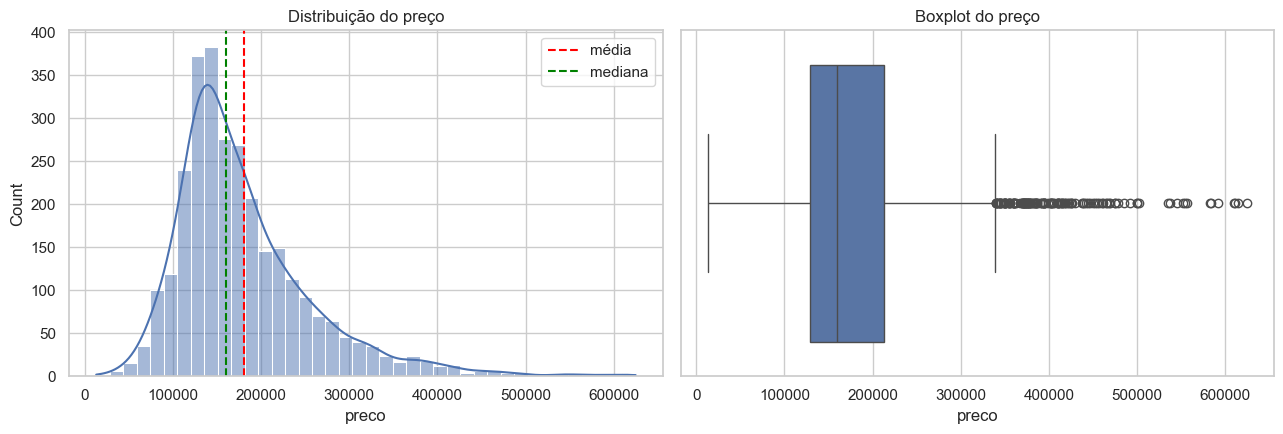

Assimetria: 1.59


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['preco'], bins=40, kde=True, ax=axes[0])
axes[0].axvline(df['preco'].mean(), color='red', linestyle='--', label='média')
axes[0].axvline(df['preco'].median(), color='green', linestyle='--', label='mediana')
axes[0].set_title('Distribuição do preço')
axes[0].legend()
sns.boxplot(x=df['preco'], ax=axes[1])
axes[1].set_title('Boxplot do preço')
plt.tight_layout()
plt.show()
print('Assimetria:', round(stats.skew(df['preco']), 2))

A distribuição é **assimétrica à direita**: a maioria das casas custa entre 130 e 215 mil dólares, mas existem algumas casas muito caras que puxam a média para cima. Por isso a **média é maior que a mediana**. O boxplot mostra vários valores altos; eles foram mantidos porque são casas reais de alto padrão, não erros.

### 5.2 Quais variáveis têm mais relação com o preço?

O coeficiente de **correlação de Pearson** mede a força da relação linear entre duas variáveis numéricas, de −1 a +1.

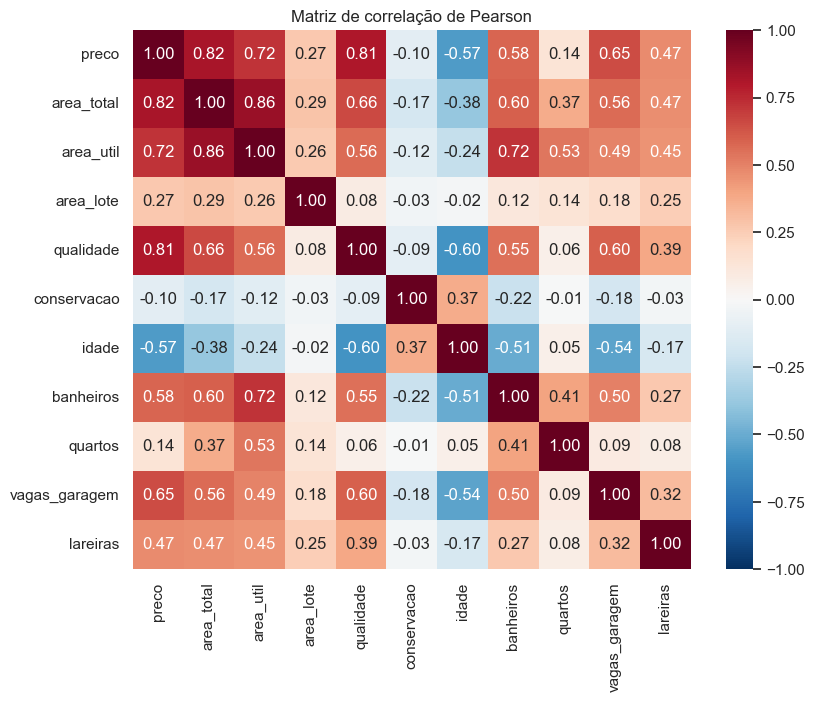

In [12]:
numericas = ['preco', 'area_total', 'area_util', 'area_lote', 'qualidade', 'conservacao', 'idade', 'banheiros', 'quartos', 'vagas_garagem', 'lareiras']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[numericas].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Matriz de correlação de Pearson')
plt.show()

As variáveis mais correlacionadas com o preço são a **área total** e a **qualidade**, seguidas das vagas de garagem e dos banheiros. A **idade** tem correlação negativa: quanto mais velha a casa, menor o preço.

A matriz também mostra que algumas variáveis explicativas são correlacionadas entre si (por exemplo, banheiros com área total). Isso será levado em conta na escolha das variáveis da regressão.

### 5.3 Preço × área e preço × qualidade

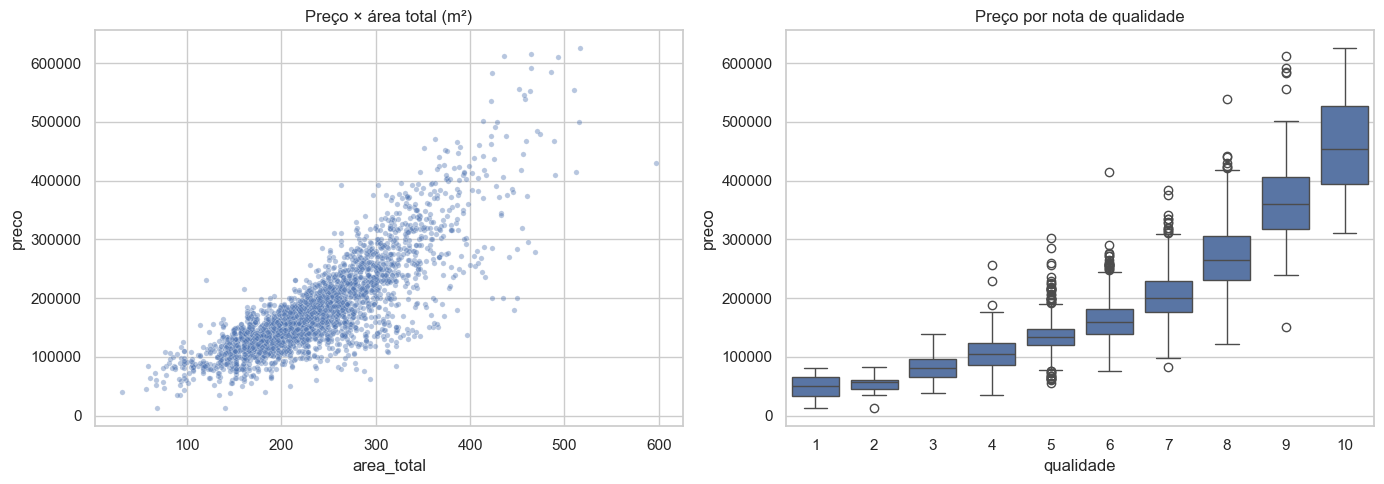

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='area_total', y='preco', alpha=0.4, s=15, ax=axes[0])
axes[0].set_title('Preço × área total (m²)')
sns.boxplot(data=df, x='qualidade', y='preco', ax=axes[1])
axes[1].set_title('Preço por nota de qualidade')
plt.tight_layout()
plt.show()

O preço cresce com a área de forma aproximadamente linear, mas os pontos ficam **mais espalhados nas casas grandes**. O preço também sobe a cada nota de qualidade, e sobe cada vez mais rápido nas notas altas.

### 5.4 Preço por bairro

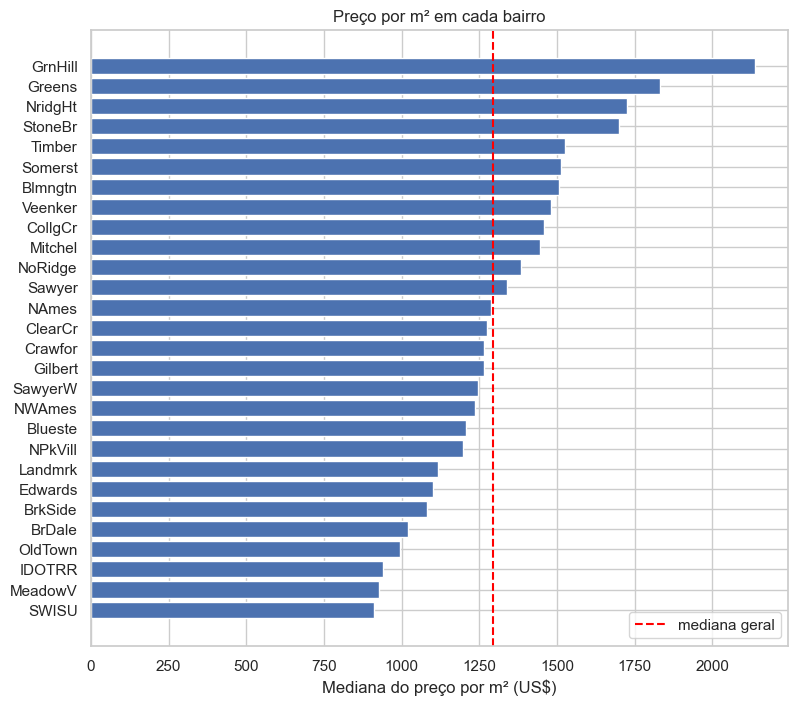

In [14]:
por_bairro = df.groupby('bairro')['preco_m2'].agg(['count', 'median']).sort_values('median')
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(por_bairro.index, por_bairro['median'])
ax.axvline(df['preco_m2'].median(), color='red', linestyle='--', label='mediana geral')
ax.set_xlabel('Mediana do preço por m² (US$)')
ax.set_title('Preço por m² em cada bairro')
ax.legend()
plt.show()

Mesmo comparando o preço **por m²**, os bairros são bem diferentes entre si: a localização tem valor próprio.

### 5.5 Vendas ao longo do tempo

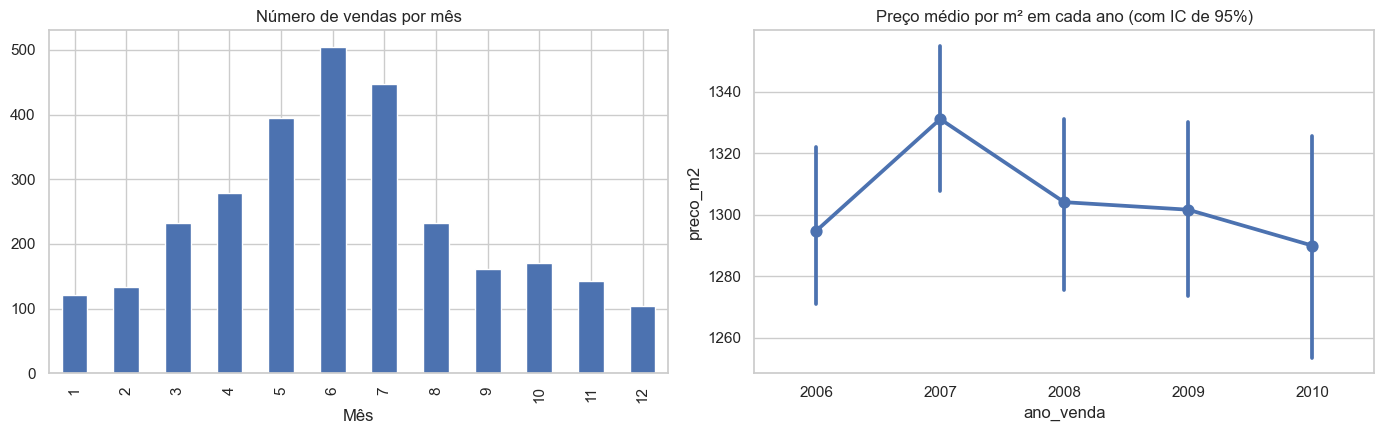

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df['mes_venda'].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title('Número de vendas por mês')
axes[0].set_xlabel('Mês')
sns.pointplot(data=df, x='ano_venda', y='preco_m2', errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Preço médio por m² em cada ano (com IC de 95%)')
plt.tight_layout()
plt.show()

As vendas se concentram entre **maio e julho** (verão nos EUA). Já o preço por m² parece **estável de 2006 a 2010**, mesmo com a crise imobiliária de 2008 — os intervalos de confiança dos anos se sobrepõem.

### 5.6 Ar-condicionado central e tipo de imóvel

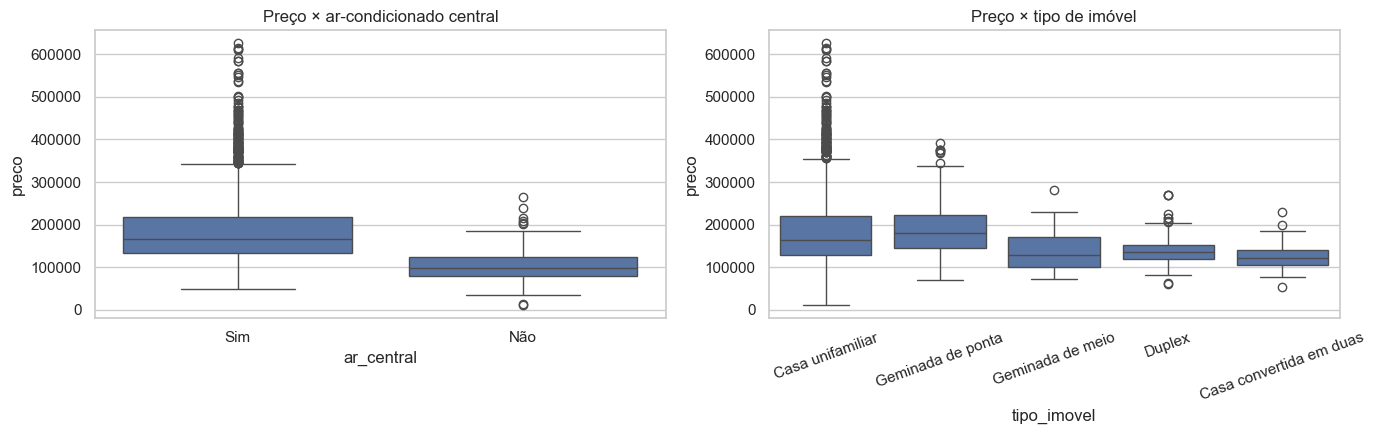

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x='ar_central', y='preco', ax=axes[0])
axes[0].set_title('Preço × ar-condicionado central')
sns.boxplot(data=df, x='tipo_imovel', y='preco', ax=axes[1])
axes[1].set_title('Preço × tipo de imóvel')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

### 5.7 Hipóteses levantadas

A partir dos gráficos, formulamos as perguntas que serão testadas:

| # | Pergunta | Teste |
|---|---|---|
| 1 | Qual é o preço médio de uma casa em Ames? | Intervalo de confiança da média |
| 2 | Casas com ar central são mais caras? | Teste t para duas amostras |
| 3 | A crise de 2008 mudou o preço por m²? | Teste t para duas amostras |
| 4 | O preço médio é diferente entre os tipos de imóvel? | ANOVA |
| 5 | Ter lareira está associado a estar na metade mais cara? | Qui-quadrado de independência |
| 6 | A relação entre área e preço é significativa? | Teste da correlação de Pearson |

## 6. Testes de hipóteses e intervalos de confiança

Em todos os testes usamos **nível de significância de 5% (α = 0,05)**:
- **H₀ (hipótese nula):** não existe diferença ou relação.
- **H₁ (hipótese alternativa):** existe.
- **p-valor:** probabilidade de observar um resultado tão extremo quanto o nosso **se H₀ fosse verdadeira**. Se p < 0,05, rejeitamos H₀.

### 6.1 Intervalo de confiança para o preço médio

Fórmula: média ± t × (desvio padrão ÷ √n), com n − 1 graus de liberdade. Usamos a distribuição **t de Student** porque o desvio padrão da população é desconhecido e foi estimado pela amostra.

In [17]:
n = len(df)
media = df['preco'].mean()
erro_padrao = df['preco'].std() / np.sqrt(n)
ic = stats.t.interval(0.95, n - 1, loc=media, scale=erro_padrao)
print(f'n = {n} | graus de liberdade = {n - 1}')
print(f'Média = {media:,.0f} | erro padrão = {erro_padrao:,.0f}')
print(f'IC de 95%: de {ic[0]:,.0f} até {ic[1]:,.0f}')

n = 2925 | graus de liberdade = 2924
Média = 180,412 | erro padrão = 1,452
IC de 95%: de 177,564 até 183,260


**Interpretação:** com 95% de confiança, o preço médio das casas de Ames está dentro desse intervalo. O intervalo é estreito (cerca de 3 mil dólares para cada lado) porque a amostra é grande.

Mesmo com o preço sendo assimétrico, o intervalo é válido: pelo **Teorema Central do Limite**, a média de uma amostra grande tem distribuição aproximadamente normal.

### 6.2 Casas com ar-condicionado central são mais caras?

- H₀: o preço médio é igual nos dois grupos.
- H₁: o preço médio é diferente.

Usamos o **teste t para duas amostras independentes**. Como os grupos têm tamanhos muito diferentes, primeiro verificamos com o **teste de Levene** se as variâncias são iguais. Se não forem, usamos a versão de **Welch** do teste t, que não exige variâncias iguais.

In [18]:
com_ar = df.loc[df['ar_central'] == 'Sim', 'preco']
sem_ar = df.loc[df['ar_central'] == 'Não', 'preco']
print(f'Com ar: n = {len(com_ar)}, média = {com_ar.mean():,.0f}, desvio padrão = {com_ar.std():,.0f}')
print(f'Sem ar: n = {len(sem_ar)}, média = {sem_ar.mean():,.0f}, desvio padrão = {sem_ar.std():,.0f}')

levene = stats.levene(com_ar, sem_ar)
print(f'\nLevene: estatística = {levene.statistic:.2f}, p-valor = {levene.pvalue:.4f}')

teste = stats.ttest_ind(com_ar, sem_ar, equal_var=False)
ic = teste.confidence_interval(0.95)
print(f'Teste t de Welch: t = {teste.statistic:.2f}, graus de liberdade = {teste.df:.0f}, p-valor = {teste.pvalue:.2e}')
print(f'Diferença das médias = {com_ar.mean() - sem_ar.mean():,.0f} | IC de 95%: de {ic.low:,.0f} até {ic.high:,.0f}')

Com ar: n = 2729, média = 186,051, desvio padrão = 77,707
Sem ar: n = 196, média = 101,890, desvio padrão = 37,597

Levene: estatística = 41.85, p-valor = 0.0000
Teste t de Welch: t = 27.41, graus de liberdade = 331, p-valor = 3.75e-87
Diferença das médias = 84,161 | IC de 95%: de 78,121 até 90,200


**Conclusão:** o Levene rejeitou a igualdade das variâncias, então usamos Welch. O p-valor é muito menor que 0,05: **rejeitamos H₀**. Casas com ar central custam, em média, cerca de 84 mil dólares a mais, e o intervalo de confiança da diferença não inclui o zero.

**Cuidado na interpretação:** isso não significa que instalar ar-condicionado aumenta o preço em 84 mil dólares. Casas sem ar central costumam ser mais antigas e menores. O teste mostra uma **associação**, não uma relação de causa e efeito.

### 6.3 A crise de 2008 mudou o preço por m²?

- H₀: o preço médio por m² é igual antes (2006–07) e depois (2009–10) de 2008.
- H₁: é diferente.

In [19]:
antes = df.loc[df['periodo'] == 'Antes de 2008', 'preco_m2']
depois = df.loc[df['periodo'] == 'Depois de 2008', 'preco_m2']
print(f'Antes:  n = {len(antes)}, média = {antes.mean():,.1f}')
print(f'Depois: n = {len(depois)}, média = {depois.mean():,.1f}')

levene = stats.levene(antes, depois)
print(f'\nLevene: p-valor = {levene.pvalue:.4f}')
teste = stats.ttest_ind(depois, antes, equal_var=False)
ic = teste.confidence_interval(0.95)
print(f'Teste t de Welch: t = {teste.statistic:.2f}, graus de liberdade = {teste.df:.0f}, p-valor = {teste.pvalue:.3f}')
print(f'Diferença (depois − antes) = {depois.mean() - antes.mean():,.1f} | IC de 95%: de {ic.low:,.1f} até {ic.high:,.1f}')

Antes:  n = 1315, média = 1,313.8
Depois: n = 989, média = 1,297.6

Levene: p-valor = 0.0021
Teste t de Welch: t = -1.11, graus de liberdade = 2025, p-valor = 0.268
Diferença (depois − antes) = -16.2 | IC de 95%: de -44.9 até 12.5


**Conclusão:** o p-valor é maior que 0,05, então **não rejeitamos H₀**. Não há evidência de que o preço por m² tenha mudado depois de 2008. O intervalo de confiança da diferença inclui o zero e é estreito, ou seja, se houve alguma queda, ela foi pequena.

Uma possível explicação é que Ames é uma cidade universitária, com procura estável por moradia. Esse resultado é importante para a regressão: como os preços ficaram estáveis, faz sentido usar os anos anteriores para prever o ano seguinte.

### 6.4 O preço médio é diferente entre os tipos de imóvel?

São 5 tipos de imóvel. Fazer vários testes t dois a dois aumentaria a chance de erro, então usamos a **ANOVA**, que compara todas as médias de uma vez.

- H₀: todas as médias são iguais.
- H₁: pelo menos uma média é diferente.
- Graus de liberdade: entre grupos = k − 1; dentro dos grupos = n − k (k = número de grupos).

In [20]:
grupos = [g['preco'] for _, g in df.groupby('tipo_imovel')]
k = len(grupos)
anova = stats.f_oneway(*grupos)
print(df.groupby('tipo_imovel')['preco'].agg(['count', 'mean', 'std']))
print(f'\nANOVA: F({k - 1}, {n - k}) = {anova.statistic:.2f}, p-valor = {anova.pvalue:.2e}')

                         count       mean       std
tipo_imovel                                        
Casa convertida em duas     62 125,581.71 31,089.24
Casa unifamiliar          2420 184,355.62 81,295.99
Duplex                     109 139,808.94 39,498.97
Geminada de meio           101 135,934.06 41,938.93
Geminada de ponta          233 192,311.91 66,191.74

ANOVA: F(4, 2920) = 26.69, p-valor = 8.87e-22


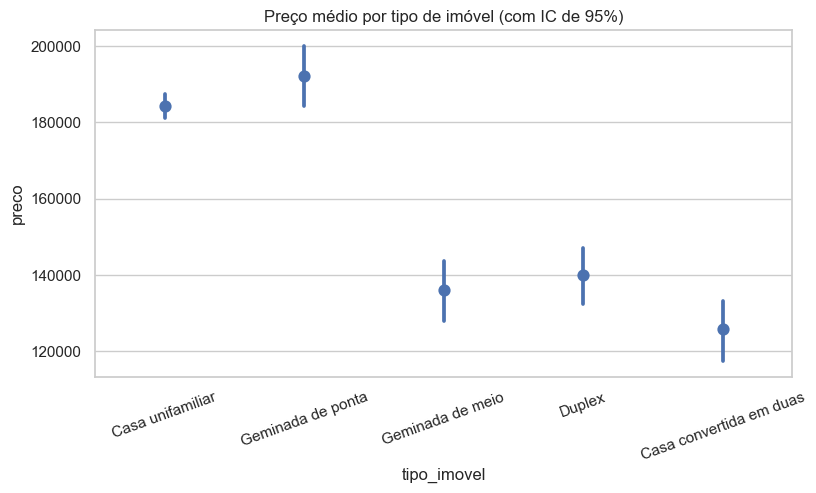

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.pointplot(data=df, x='tipo_imovel', y='preco', errorbar=('ci', 95), linestyle='none', ax=ax)
ax.set_title('Preço médio por tipo de imóvel (com IC de 95%)')
ax.tick_params(axis='x', rotation=20)
plt.show()

**Conclusão:** p-valor menor que 0,05: **rejeitamos H₀**. Pelo menos um tipo de imóvel tem preço médio diferente. O gráfico com os intervalos de confiança mostra quais: casas unifamiliares e geminadas de ponta têm médias mais altas, e os intervalos delas não se sobrepõem aos dos outros três tipos.

**Limitação:** a ANOVA diz que existe diferença, mas não diz entre quais grupos. Para isso seria necessário um teste de comparações múltiplas (como o de Tukey). Aqui usamos os intervalos de confiança do gráfico como apoio.

### 6.5 Ter lareira está associado à faixa de preço?

As duas variáveis são categóricas, então usamos o **qui-quadrado de independência**, que compara as frequências observadas com as que seriam esperadas se não houvesse relação.

- H₀: ter lareira e faixa de preço são independentes.
- H₁: existe associação.
- Graus de liberdade = (linhas − 1) × (colunas − 1) = 1.

In [22]:
tabela = pd.crosstab(df['tem_lareira'], df['faixa_preco'])
qui2, p_valor, gl, esperado = stats.chi2_contingency(tabela)
print(tabela)
print('\nFrequências esperadas se fossem independentes:')
print(pd.DataFrame(esperado, index=tabela.index, columns=tabela.columns).round(0))
print(f'\nQui-quadrado = {qui2:.1f}, graus de liberdade = {gl}, p-valor = {p_valor:.2e}')
print('\nPercentual em cada faixa de preço:')
print((pd.crosstab(df['tem_lareira'], df['faixa_preco'], normalize='index') * 100).round(1))

faixa_preco  Abaixo da mediana  Acima da mediana
tem_lareira                                     
Não                       1058               364
Sim                        408              1095

Frequências esperadas se fossem independentes:
faixa_preco  Abaixo da mediana  Acima da mediana
tem_lareira                                     
Não                     713.00            709.00
Sim                     753.00            750.00

Qui-quadrado = 650.8, graus de liberdade = 1, p-valor = 1.48e-143

Percentual em cada faixa de preço:
faixa_preco  Abaixo da mediana  Acima da mediana
tem_lareira                                     
Não                      74.40             25.60
Sim                      27.10             72.90


**Conclusão:** **rejeitamos H₀**. As frequências observadas são muito diferentes das esperadas: entre as casas com lareira, a grande maioria está na metade mais cara; entre as sem lareira, acontece o contrário. Todas as frequências esperadas são maiores que 5, que é a condição para usar o teste.

### 6.6 A correlação entre área e preço é significativa?

- H₀: a correlação na população é zero.
- H₁: é diferente de zero.

In [23]:
teste = stats.pearsonr(df['area_total'], df['preco'])
ic = teste.confidence_interval(0.95)
print(f'r = {teste.statistic:.3f} | IC de 95%: de {ic.low:.3f} até {ic.high:.3f} | p-valor = {teste.pvalue:.2e}')

r = 0.825 | IC de 95%: de 0.813 até 0.836 | p-valor = 0.00e+00


**Conclusão:** correlação **forte e positiva**, com intervalo de confiança bem longe do zero. **Rejeitamos H₀.** Isso justifica começar a regressão pela área.

### 6.7 Resumo dos testes

| Pergunta | Teste | Resultado |
|---|---|---|
| Ar central × preço | t de Welch | Diferença significativa |
| Crise de 2008 × preço/m² | t de Welch | **Sem** diferença significativa |
| Tipo de imóvel × preço | ANOVA | Diferença significativa |
| Lareira × faixa de preço | Qui-quadrado | Associação significativa |
| Área × preço | Correlação de Pearson | Correlação significativa |

## 7. Regressão linear

### 7.1 Divisão em treino e teste

Para avaliar se o modelo consegue **prever valores futuros**, separamos os dados pelo tempo:
- **Treino:** vendas de 2006 a 2009 (o modelo aprende com elas).
- **Teste:** vendas de 2010 (o modelo nunca viu esses dados).

É mais realista do que sortear as linhas, porque na prática sempre usamos o passado para prever o futuro.

In [24]:
treino = df[df['ano_venda'] <= 2009]
teste = df[df['ano_venda'] == 2010]
print(f'Treino: {len(treino)} casas | Teste: {len(teste)} casas')

Treino: 2584 casas | Teste: 341 casas


### 7.2 Regressão linear simples: preço em função da área

Modelo: **preço = β₀ + β₁ × área total + erro**. Os coeficientes são estimados pelo método dos **mínimos quadrados**, que escolhe a reta com a menor soma dos erros ao quadrado.

In [25]:
modelo_simples = smf.ols('preco ~ area_total', data=treino).fit()
print(modelo_simples.summary().tables[1])
print(f'\nR² = {modelo_simples.rsquared:.3f}')

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -3.663e+04   3036.961    -12.062      0.000   -4.26e+04   -3.07e+04
area_total   921.6913     12.295     74.966      0.000     897.583     945.800

R² = 0.685


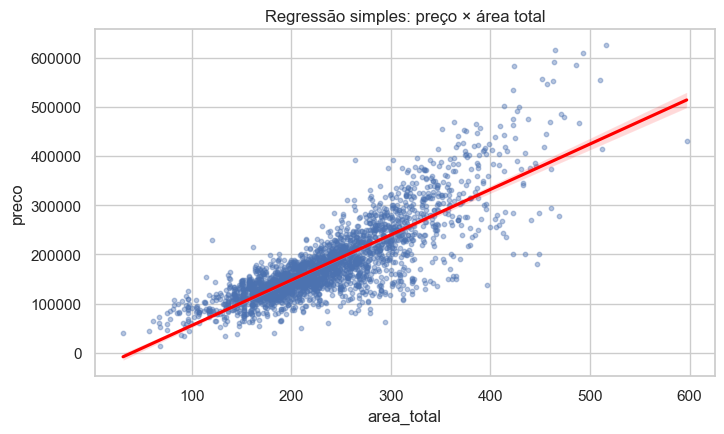

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=treino, x='area_total', y='preco', scatter_kws={'s': 10, 'alpha': 0.4}, line_kws={'color': 'red'}, ax=ax)
ax.set_title('Regressão simples: preço × área total')
plt.show()

**Interpretação:**
- **Inclinação (β₁):** cada m² a mais de área total está associado a um aumento de cerca de 920 dólares no preço. O intervalo de confiança não inclui o zero e o p-valor é menor que 0,05, então o efeito é significativo.
- **R²:** a área sozinha explica cerca de 69% da variação dos preços.
- **Intercepto (β₀):** é negativo e não tem interpretação prática, porque não existe casa com área zero.

### 7.3 Regressão linear múltipla

Só a área não basta: duas casas do mesmo tamanho podem ter preços bem diferentes. Adicionamos outras características.

**Escolha das variáveis:**
- `area_total`, `qualidade`, `vagas_garagem`, `lareiras`: maiores correlações com o preço.
- `idade` e `conservacao`: representam o desgaste da casa.

**Variáveis que testamos e deixamos de fora:**
- `banheiros`: tem correlação de 0,60 com a área total. Quando duas variáveis explicativas são muito relacionadas (**multicolinearidade**), o modelo não consegue separar o efeito de cada uma, e o coeficiente de banheiros saiu negativo e não significativo (p = 0,05), o que não faz sentido prático.
- `ar_central`: 93% das casas têm, e as que não têm são as mais antigas. Quando incluído, o coeficiente saiu negativo, o contrário do que o teste t mostrou, porque o efeito fica misturado com o da idade e da qualidade.
- `area_util` e `quartos`: já estão representadas pela área total.

In [27]:
modelo = smf.ols('preco ~ area_total + qualidade + conservacao + idade + vagas_garagem + lareiras', data=treino).fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.830
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     2103.
Date:                Wed, 07 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:36:24   Log-Likelihood:                -30514.
No. Observations:                2584   AIC:                         6.104e+04
Df Residuals:                    2577   BIC:                         6.108e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -9.513e+04   5051.429    -18.833

**Como ler a tabela:**
- **coef:** efeito de aumentar a variável em 1 unidade, **mantendo as outras constantes**.
- **P>|t|:** p-valor do teste de H₀: coeficiente = 0. Todos são menores que 0,05, então todas as variáveis são significativas.
- **[0.025, 0.975]:** intervalo de confiança de 95% do coeficiente.
- **F-statistic:** testa se o modelo como um todo explica alguma coisa (H₀: todos os coeficientes são zero). Foi rejeitada.
- **R² ajustado:** igual ao R², mas penaliza o número de variáveis. Serve para comparar modelos com quantidades diferentes de variáveis.

**Interpretação dos coeficientes** (mantendo as demais variáveis constantes):
- cada **m²** a mais: cerca de +530 dólares;
- cada ponto de **qualidade**: cerca de +17 mil dólares;
- cada ponto de **conservação**: cerca de +6 mil dólares;
- cada **ano de idade**: cerca de −420 dólares;
- cada **vaga de garagem**: cerca de +10 mil dólares;
- cada **lareira**: cerca de +9 mil dólares.

O efeito do m² caiu de 920 (regressão simples) para 530. Isso acontece porque, na regressão simples, a área "levava o crédito" por coisas que andam junto com ela, como a qualidade e a garagem.

In [28]:
coeficientes = pd.DataFrame({
    'coeficiente': modelo.params,
    'IC 95% inferior': modelo.conf_int()[0],
    'IC 95% superior': modelo.conf_int()[1],
    'p-valor': modelo.pvalues,
}).drop('Intercept')
coeficientes

,coeficiente,IC 95% inferior,IC 95% superior,p-valor
area_total,534.65,508.17,561.12,0.00
qualidade,"17,335.24","15,878.18","18,792.31",0.00
conservacao,"6,390.44","5,124.38","7,656.49",0.00
idade,-423.39,-482.12,-364.66,0.00
vagas_garagem,"10,289.40","8,036.15","12,542.65",0.00
lareiras,"9,251.88","7,007.69","11,496.06",0.00


### 7.4 Desempenho do modelo e previsão para 2010

Métricas usadas:
- **R²:** proporção da variação do preço explicada pelo modelo.
- **RMSE:** raiz do erro quadrático médio; dá mais peso aos erros grandes.
- **MAE:** erro absoluto médio; é o erro "típico" em dólares.

In [29]:
def avaliar(modelo, dados):
    previsto = modelo.predict(dados)
    return {
        'R²': r2_score(dados['preco'], previsto),
        'RMSE (US$)': np.sqrt(mean_squared_error(dados['preco'], previsto)),
        'MAE (US$)': mean_absolute_error(dados['preco'], previsto),
    }


desempenho = pd.DataFrame({
    'Simples - treino': avaliar(modelo_simples, treino),
    'Simples - teste (2010)': avaliar(modelo_simples, teste),
    'Múltipla - treino': avaliar(modelo, treino),
    'Múltipla - teste (2010)': avaliar(modelo, teste),
}).T
desempenho

,R²,RMSE (US$),MAE (US$)
Simples - treino,0.69,"44,324.38","31,450.26"
Simples - teste (2010),0.64,"44,892.11","31,990.57"
Múltipla - treino,0.83,"32,531.42","23,043.50"
Múltipla - teste (2010),0.82,"31,311.53","21,478.65"


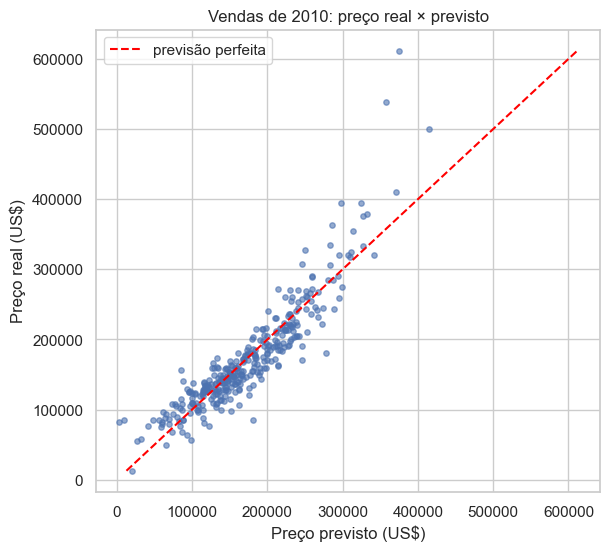

In [30]:
previsto = modelo.predict(teste)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(previsto, teste['preco'], s=15, alpha=0.6)
limites = [teste['preco'].min(), teste['preco'].max()]
ax.plot(limites, limites, color='red', linestyle='--', label='previsão perfeita')
ax.set_xlabel('Preço previsto (US$)')
ax.set_ylabel('Preço real (US$)')
ax.set_title('Vendas de 2010: preço real × previsto')
ax.legend()
plt.show()

**Leitura:**
- O modelo múltiplo explica cerca de **83%** da variação dos preços no treino e **82%** nas vendas de 2010. Como os dois valores são próximos, o modelo **não decorou os dados de treino** (não há overfitting) e consegue prever dados novos.
- O erro típico (MAE) é de cerca de 21 mil dólares, contra 32 mil da regressão simples.
- No gráfico, os pontos acompanham a linha vermelha. Nas casas mais caras, o modelo tende a prever **abaixo** do preço real.

### 7.5 Verificação dos pressupostos

A regressão linear supõe que os **resíduos** (preço real − preço previsto):
1. não têm padrão em relação aos valores previstos (**linearidade**);
2. têm espalhamento constante (**homocedasticidade**);
3. têm distribuição aproximadamente **normal**.

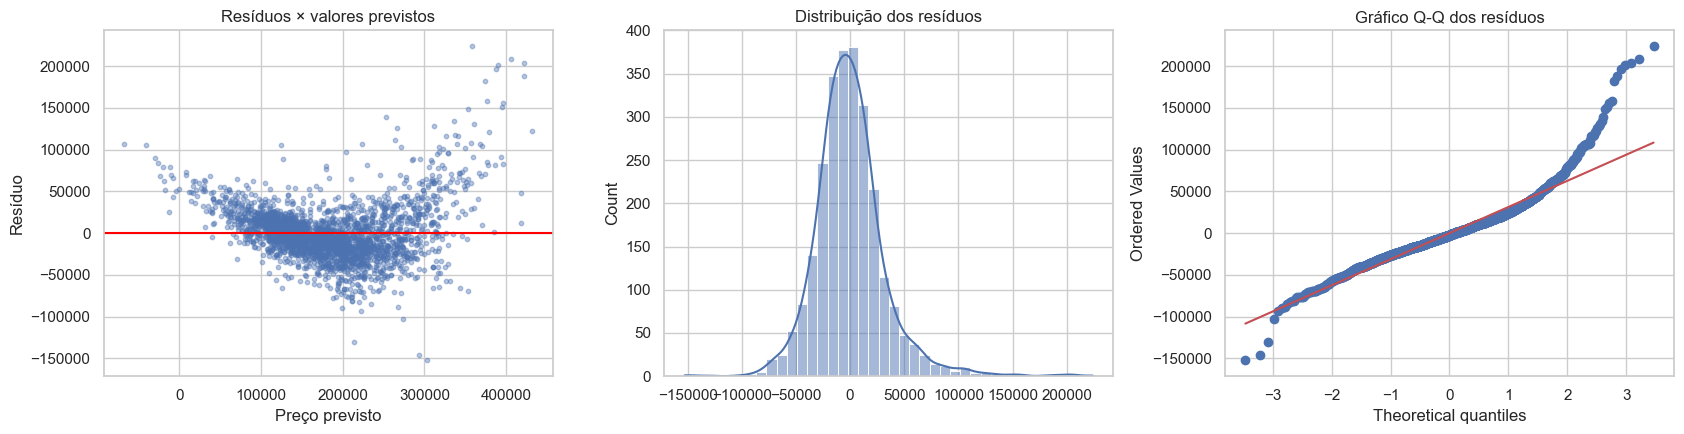

In [31]:
residuos = modelo.resid
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(modelo.fittedvalues, residuos, s=10, alpha=0.4)
axes[0].axhline(0, color='red')
axes[0].set_xlabel('Preço previsto')
axes[0].set_ylabel('Resíduo')
axes[0].set_title('Resíduos × valores previstos')
sns.histplot(residuos, bins=40, kde=True, ax=axes[1])
axes[1].set_title('Distribuição dos resíduos')
stats.probplot(residuos, dist='norm', plot=axes[2])
axes[2].set_title('Gráfico Q-Q dos resíduos')
plt.tight_layout()
plt.show()

**Avaliação honesta:**
- **Linearidade:** os resíduos formam uma leve curva em "U": o modelo erra para baixo nas casas mais baratas e nas mais caras. A relação não é perfeitamente linear.
- **Homocedasticidade:** o espalhamento **aumenta** nas casas mais caras (formato de funil). Ou seja, o pressuposto não é totalmente atendido, e o modelo é menos preciso para casas de alto padrão.
- **Normalidade:** o histograma é simétrico e em forma de sino no centro, mas o gráfico Q-Q mostra pontos fora da reta nas pontas (alguns erros muito grandes).

**Consequência:** os coeficientes continuam sendo boas estimativas, mas os intervalos de confiança e de predição devem ser lidos com cautela, principalmente para casas caras. Uma melhoria possível seria modelar o **logaritmo do preço**, que costuma corrigir o funil e a curva.

### 7.6 Exemplo de previsão

Casa de 230 m², qualidade 6, conservação 5, 20 anos, 2 vagas e 1 lareira.

In [32]:
casa = pd.DataFrame([{'area_total': 230, 'qualidade': 6, 'conservacao': 5, 'idade': 20, 'vagas_garagem': 2, 'lareiras': 1}])
previsao = modelo.get_prediction(casa).summary_frame(alpha=0.05)
print(f"Preço previsto: {previsao['mean'][0]:,.0f}")
print(f"IC de 95% da média: de {previsao['mean_ci_lower'][0]:,.0f} até {previsao['mean_ci_upper'][0]:,.0f}")
print(f"Intervalo de predição de 95%: de {previsao['obs_ci_lower'][0]:,.0f} até {previsao['obs_ci_upper'][0]:,.0f}")

Preço previsto: 185,164
IC de 95% da média: de 183,254 até 187,074
Intervalo de predição de 95%: de 121,258 até 249,069


- **Intervalo de confiança da média:** onde está o preço **médio** de todas as casas com essas características. É estreito.
- **Intervalo de predição:** onde deve estar o preço de **uma casa específica**. É bem mais largo, porque inclui a variação natural entre casas parecidas.

## 8. Conclusões e recomendações

### 8.1 O que descobrimos
1. **Tamanho e qualidade** são os fatores que mais explicam o preço.
2. Com seis características simples, o modelo explica cerca de **82%** da variação dos preços de um ano que ele não conhecia.
3. A **crise de 2008 não alterou** de forma significativa o preço por m² em Ames.
4. As vendas se concentram entre **maio e julho**.
5. Casas com **ar central** e com **lareira** estão associadas a preços maiores, mas parte disso se deve a serem casas mais novas e maiores.

### 8.2 Recomendações práticas
| Para quem | Recomendação | Base |
|---|---|---|
| Quem vai vender | Usar o modelo para ter uma faixa de preço de referência antes de anunciar, olhando o intervalo de predição e não só o valor previsto. | Regressão múltipla, R² de 0,82 em 2010 |
| Quem vai reformar | Priorizar melhorias que aumentem a nota de **qualidade** e de **conservação**: cada ponto vale cerca de 17 mil e 6 mil dólares. Comparar esse ganho com o custo da obra. | Coeficientes e intervalos de confiança |
| Quem vai construir ou ampliar | Uma vaga de garagem a mais vale cerca de 10 mil dólares, o equivalente a uns 19 m² de área construída. | Coeficientes da regressão |
| Quem vai comprar | Comparar o preço pedido com o previsto pelo modelo: casas muito abaixo do previsto podem ser oportunidades (ou ter problemas que os dados não mostram). | Resíduos do modelo |
| Quem vai vender | Os meses de maio a julho têm mais negócios fechados. | Análise descritiva (não testamos formalmente) |

### 8.3 Limitações
- Os dados são de **uma única cidade** dos EUA, de 2006 a 2010. Os resultados não valem automaticamente para outros lugares ou épocas.
- Os dados são **observacionais**: mostram associações, não provam causa e efeito.
- O modelo não usa a **localização** (bairro), que a análise descritiva mostrou ser importante.
- Os resíduos mostram **variância crescente** e uma leve curva: o modelo é menos confiável para casas muito caras.
- Não temos o **custo** das reformas, então não dá para calcular o lucro de cada melhoria.

## 9. Exportação da base tratada para o dashboard

In [33]:
df.to_csv('dados_tratados.csv', index=False)
print(df.shape)
df.columns.tolist()

(2925, 28)


['preco',
 'area_util',
 'area_porao',
 'area_lote',
 'frente_lote',
 'qualidade',
 'conservacao',
 'ano_construcao',
 'ano_reforma',
 'ano_venda',
 'mes_venda',
 'banheiros_completos',
 'lavabos',
 'quartos',
 'vagas_garagem',
 'tipo_garagem',
 'lareiras',
 'ar_central',
 'bairro',
 'tipo_imovel',
 'area_total',
 'idade',
 'reformada',
 'banheiros',
 'tem_lareira',
 'preco_m2',
 'faixa_preco',
 'periodo']